<a href="https://colab.research.google.com/github/SanthoshKumar-L/MLA0201---Fundamentals-of-ML/blob/main/ML_EXP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

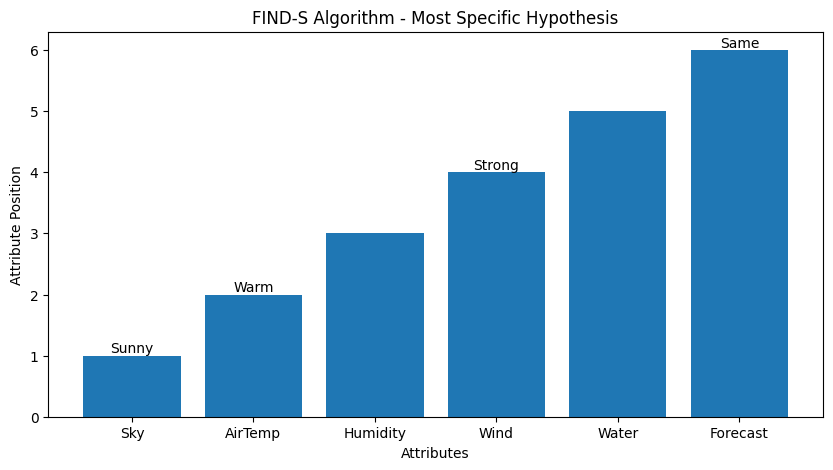

In [ ]:
import matplotlib.pyplot as plt

attributes = ['Sky', 'AirTemp', 'Humidity', 'Wind', 'Water', 'Forecast']
# Remove all '?' symbols as requested (replaced with empty strings)
hypothesis = ['Sunny', 'Warm', '', 'Strong', '', 'Same']

plt.figure(figsize=(10, 5))
plt.bar(attributes, range(1, 7))

for i in range(len(attributes)):
    plt.text(i, i + 1, hypothesis[i], ha='center', va='bottom')

plt.xlabel("Attributes")
plt.ylabel("Attribute Position")
plt.title("FIND-S Algorithm - Most Specific Hypothesis")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Same'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}
pd.DataFrame(csv_data).to_csv('training_data.csv', index=False)

def candidate_elimination(csv_path):
    df = pd.read_csv(csv_path)
    concepts = df.iloc[:, :-1].values
    target = df.iloc[:, -1].values
    num_attributes = concepts.shape[1]

    specific_h = list(concepts[0].copy())
    general_h = [['?' for _ in range(num_attributes)] for _ in range(num_attributes)]

    for i, val in enumerate(concepts):
        if target[i] == 'Yes':
            for x in range(num_attributes):
                if val[x] != specific_h[x]:
                    specific_h[x] = '?'
                    for g in general_h:
                        if g[x] != '?' and g[x] != specific_h[x]:
                            general_h.remove(g)
        elif target[i] == 'No':
            for x in range(num_attributes):
                if val[x] != specific_h[x]:
                    temp_g = ['?' for _ in range(num_attributes)]
                    temp_g[x] = specific_h[x]
                    if temp_g not in general_h:
                        general_h.append(temp_g)
                else:
                    for g in general_h:
                        if g[x] == val[x]:
                            general_h.remove(g)

        general_h = [g for g in general_h if any(g[x] == '?' or g[x] == specific_h[x] for x in range(num_attributes))]
        valid_g = []
        for g in general_h:
            is_more_general = True
            for x in range(num_attributes):
                if g[x] != '?' and g[x] != specific_h[x]:
                    is_more_general = False
                    break
            if is_more_general:
                valid_g.append(g)
        general_h = valid_g
        general_h = [g for g in general_h if g != ['?' for _ in range(num_attributes)]]

    return specific_h, general_h

s_final, g_final = candidate_elimination('training_data.csv')
print("Specific Boundary (S):", s_final)
print("General Boundary (G):", g_final)

Specific Boundary (S): ['Sunny', 'Warm', '?', 'Strong', '?', 'Same']
General Boundary (G): [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]


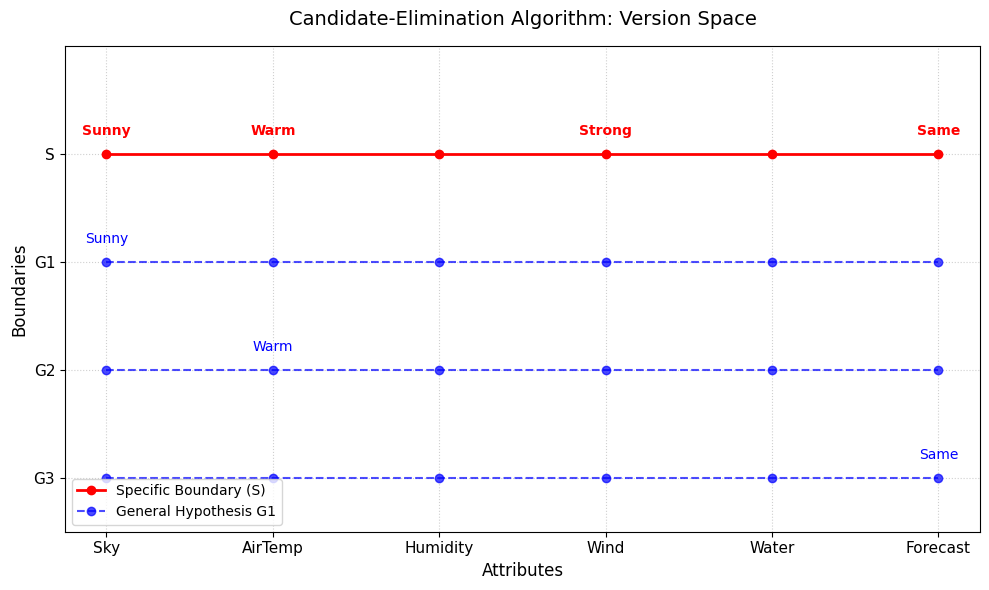

In [ ]:
attributes = ['Sky', 'AirTemp', 'Humidity', 'Wind', 'Water', 'Forecast']
s_boundary = [val if val != '?' else '' for val in s_final]
g_boundary = [[val if val != '?' else '' for val in hyp] for hyp in g_final]

fig, ax = plt.subplots(figsize=(10, 6))
x_pos = np.arange(len(attributes))

ax.plot(x_pos, [4] * len(attributes), 'ro-', linewidth=2, label='Specific Boundary (S)')
for i, val in enumerate(s_boundary):
    ax.text(i, 4.15, val, ha='center', va='bottom', color='red', fontweight='bold')

for idx, g_hyp in enumerate(g_boundary):
    y_val = 3 - idx
    ax.plot(x_pos, [y_val] * len(attributes), 'bo--', alpha=0.7, label=f'General Hypothesis G{idx+1}' if idx==0 else "")
    for i, val in enumerate(g_hyp):
        ax.text(i, y_val + 0.15, val, ha='center', va='bottom', color='blue')

ax.set_xticks(x_pos)
ax.set_xticklabels(attributes, fontsize=11)
ax.set_yticks([1, 2, 3, 4])
ax.set_yticklabels(['G3', 'G2', 'G1', 'S'], fontsize=11)
ax.set_ylim(0.5, 5.0)
ax.set_title("Candidate-Elimination Algorithm: Version Space", fontsize=14, pad=15)
ax.set_xlabel("Attributes", fontsize=12)
ax.set_ylabel("Boundaries", fontsize=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

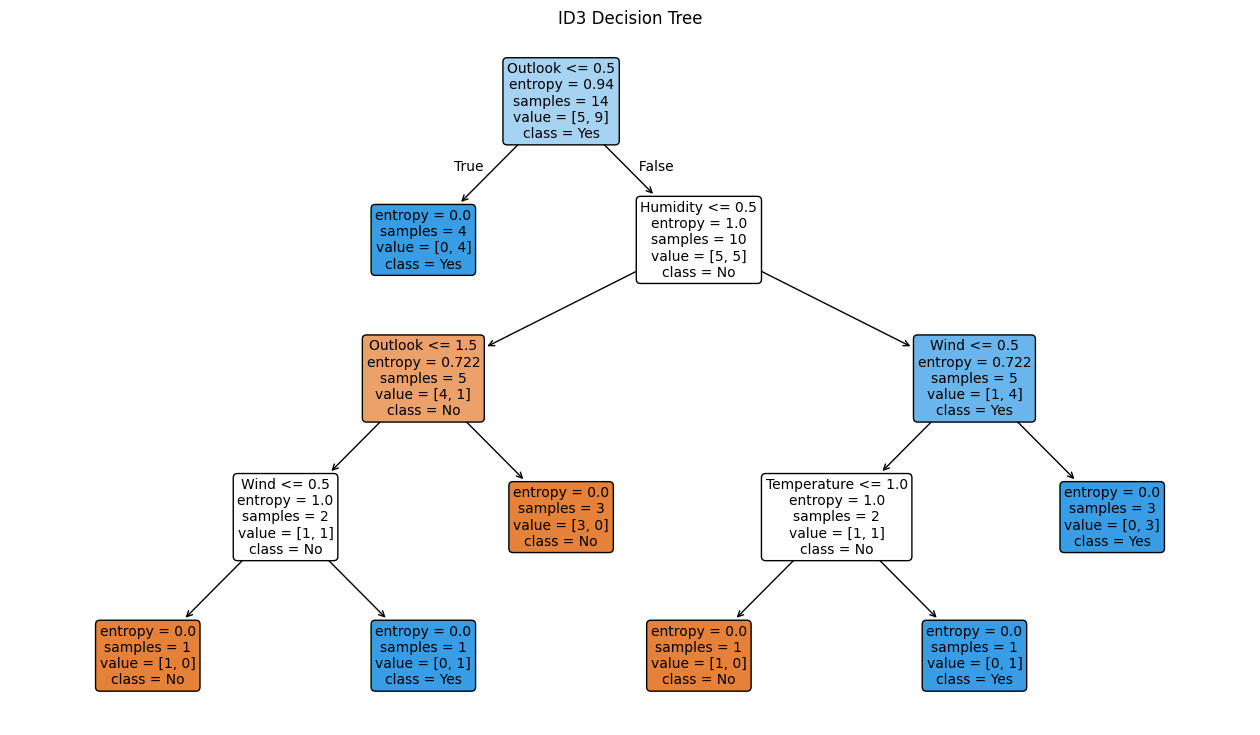

New Sample: Sunny, Cool, Normal, Weak
Classification: Yes


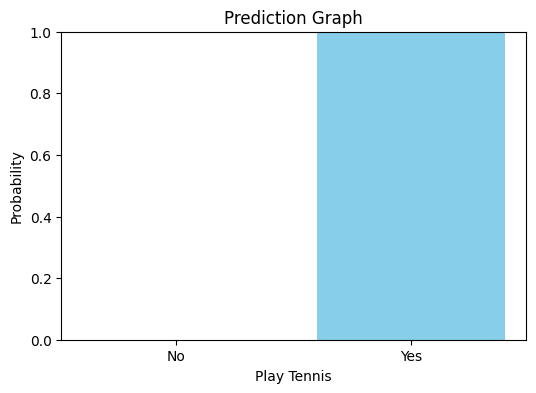

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain',
                'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast',
                'Overcast', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool',
                    'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild',
                    'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High',
                 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong',
             'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong',
             'Weak', 'Strong'],
    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes',
             'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)

encoders = {}
for col in df.columns:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col])

X = df.drop('Play', axis=1)
y = df['Play']

model = DecisionTreeClassifier(criterion='entropy', random_state=0)
model.fit(X, y)

plt.figure(figsize=(16, 9))
plot_tree(model, feature_names=X.columns,
          class_names=encoders['Play'].classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("ID3 Decision Tree")
plt.show()

sample = pd.DataFrame([{
    'Outlook': 'Sunny',
    'Temperature': 'Cool',
    'Humidity': 'Normal',
    'Wind': 'Weak'
}])

for col in sample.columns:
    sample[col] = encoders[col].transform(sample[col])

prediction = model.predict(sample)[0]

print("New Sample: Sunny, Cool, Normal, Weak")
print("Classification:",
      encoders['Play'].inverse_transform([prediction])[0])

plt.figure(figsize=(6, 4))
plt.bar(['No', 'Yes'], model.predict_proba(sample)[0],
        color=['tomato', 'skyblue'])
plt.title("Prediction Graph")
plt.xlabel("Play Tennis")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.show()

Actual Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Predicted Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Accuracy: 100.0 %


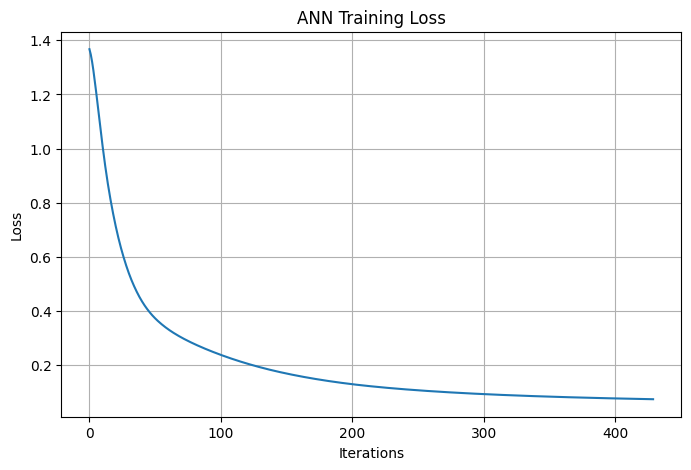

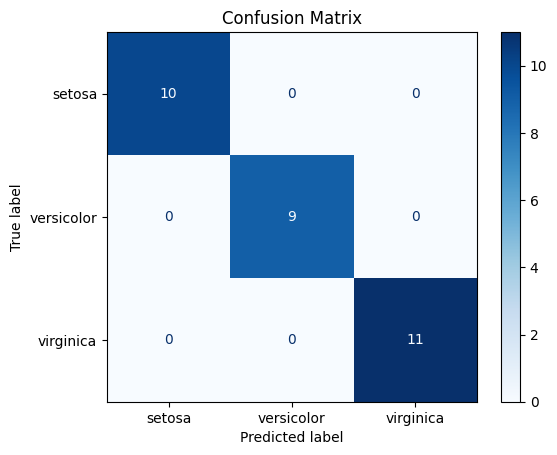

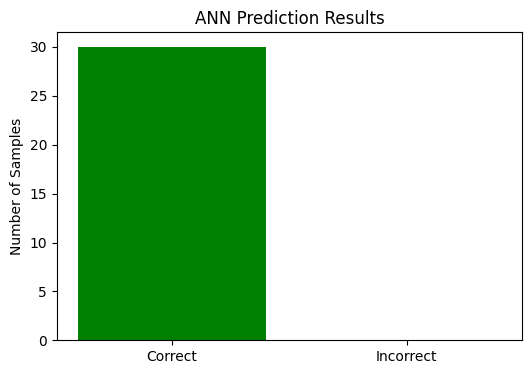

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

data = load_iris()
X = data.data
y = data.target

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation='relu',
    solver='sgd',
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Actual Values:", y_test)
print("Predicted Values:", y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

plt.figure(figsize=(8, 5))
plt.plot(model.loss_curve_)
plt.title("ANN Training Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap='Blues')

plt.title("Confusion Matrix")
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(["Correct", "Incorrect"], [
    np.sum(y_test == y_pred),
    np.sum(y_test != y_pred)
], color=['green', 'red'])
plt.title("ANN Prediction Results")
plt.ylabel("Number of Samples")
plt.show()